# Performance Evaluation: State-Diff Workload

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd
import numpy as np
import os, glob
from pathlib import Path
from typing import Dict, List, Optional, Tuple
import scienceplots

In [2]:
# ── Shared style ────────────────────────────────────────────────────────────
plt.style.use(['science', 'grid', 'no-latex', 'high-contrast'])
plt.rcParams['pdf.fonttype'] = 42   # TrueType, not Type 3
plt.rcParams['ps.fonttype'] = 42

# Engine color/hatch palette (MMap=blue, IOUring=orange, SCISSOR=green)
ENGINE_STYLE = {
    'MMap':    {'color': '#1f77b4', 'hatch': '//'},
    'IOUring': {'color': '#ff7f0e', 'hatch': '..'},
    'SCISSOR': {'color': '#2ca02c', 'hatch': 'xx'},
}

# FONT = {'title': 12, 'axis': 12, 'tick': 10, 'annot': 9}
FONT = {'title': 11, 'axis': 11, 'tick': 10, 'annot': 10}
# FIG_SIZE_DEFAULT = (6, 3)
# FIG_SIZE_WIDE    = (12, 3.5)
# FIG_SIZE_SMALL   = (3.5, 2.5)

FIG_SIZE_DEFAULT = (3.3, 2.2)        # single column
FIG_SIZE_TWOCOL  = (5.0, 2.5)        # two column (figure*)
FIG_SIZE_HALFCOL = (3.3, 2.5)
# FONT = {'title': 9, 'axis': 8, 'tick': 7, 'annot': 6, 'legend': 7}

fig_dir = "../figures"
os.makedirs(fig_dir, exist_ok=True)

## Run-to-Run Variation

Run-to-run variation is drawn on every bar.

Each bar is the **median** across repeated runs of a configuration (3 runs
for most datasets). The whiskers show the spread of those runs, selected by
`ERRBAR_MODE` in the next cell (`minmax`, `iqr`, or `std`). Figures are
written to `../figures/`.


In [3]:
# ── Run-to-run variation ────────────────────────────────────────────────────
# Every figure aggregates per-rank CSVs into one value per run, then reduces
# across runs with a median. These helpers leave that median untouched and carry
# a spread band alongside it so the bars can show run-to-run variation.
#
#   'minmax': whiskers span min..max across runs (honest at n=3)
#   'iqr':    whiskers span the 25th..75th percentile
#   'std':    whiskers span median +/- 1 standard deviation
ERRBAR_MODE = 'minmax'

ERRBAR_KW = dict(ecolor='black', capsize=2, elinewidth=0.8, capthick=0.8)

SPREAD_LO, SPREAD_HI, SPREAD_N = 'Throughput lo', 'Throughput hi', 'Throughput runs'


def median_with_spread(per_run_df, group_cols, value_col='Throughput', mode=None):
    """
    Reduce per-run rows to one row per group: the median of every numeric column
    (identical to the original .median(numeric_only=True)) plus lo/hi bounds and
    the run count for `value_col`, so plots can draw run-to-run variation.
    """
    mode = mode or ERRBAR_MODE
    grouped = per_run_df.groupby(group_cols)

    df_med = grouped.median(numeric_only=True).reset_index()
    if value_col not in per_run_df.columns:
        return df_med

    med = grouped[value_col].median()
    if mode == 'minmax':
        lo, hi = grouped[value_col].min(), grouped[value_col].max()
    elif mode == 'iqr':
        lo, hi = grouped[value_col].quantile(0.25), grouped[value_col].quantile(0.75)
    elif mode == 'std':
        sd = grouped[value_col].std().fillna(0.0)
        lo, hi = med - sd, med + sd
    else:
        raise ValueError(f"unknown ERRBAR_MODE: {mode}")

    spread = pd.DataFrame({
        SPREAD_LO: lo,
        SPREAD_HI: hi,
        SPREAD_N:  grouped[value_col].size(),
    }).reset_index()

    return df_med.merge(spread, on=group_cols, how='left')


def yerr(rows, value_col='Throughput'):
    """
    Build the (2, N) asymmetric array for ax.bar(yerr=...) from the lo/hi columns.
    Returns None when `rows` carries no spread columns, so bars drawn from data
    loaded the old way simply come out without whiskers.
    """
    if rows is None or len(rows) == 0:
        return None
    if SPREAD_LO not in rows or SPREAD_HI not in rows:
        return None
    center = np.asarray(rows[value_col], dtype=float)
    lower = np.nan_to_num(center - np.asarray(rows[SPREAD_LO], dtype=float), nan=0.0)
    upper = np.nan_to_num(np.asarray(rows[SPREAD_HI], dtype=float) - center, nan=0.0)
    return np.clip(np.vstack([lower, upper]), 0.0, None)


def top(rows, value_col='Throughput'):
    """Upper edge of each bar including its whisker, for label placement."""
    center = np.asarray(rows[value_col], dtype=float)
    if SPREAD_HI not in rows:
        return center
    hi = np.nan_to_num(np.asarray(rows[SPREAD_HI], dtype=float), nan=0.0)
    return np.fmax(center, hi)


def spread_of(row, value_col='Throughput'):
    """(lo, hi) for a single row, falling back to the point value when absent."""
    val = float(row[value_col])
    lo = float(row[SPREAD_LO]) if SPREAD_LO in row and pd.notna(row[SPREAD_LO]) else val
    hi = float(row[SPREAD_HI]) if SPREAD_HI in row and pd.notna(row[SPREAD_HI]) else val
    return lo, hi


## Helper Functions

In [4]:
def load_and_process(dirpath, error_map, extra_cols=[], nfiles=2):
    """
    Load per-rank CSV benchmark logs, aggregate across ranks per run,
    then take the median across runs.

    Throughput aggregation: ranks run in parallel behind MPI_Barrier.
    Wall-clock time = max(Compare time across ranks).
    System throughput = Σ(Processed Data GB) / max(Compare time).
    """
    csvs = glob.glob(os.path.join(dirpath, "*.csv"))
    dfs = []
    for filename in csvs:
        s_df = pd.read_csv(filename)
        dfs.append(s_df)

    df = pd.concat(dfs, ignore_index=True)

    df['Run'] = 1
    df['Run'] = df.groupby(['Rank', 'File', 'Chunk size', 'Error tolerance'] + extra_cols).Run.cumsum() - 1

    df = df[df['Num hash comparisons'] != 0]

    GB = 1_000_000_000
    df = df.rename(columns={'Compare direct time': 'Compare time'})

    df[['ckpt_rank', 'ckpt_id']] = df['File'].str.extract(r'-combined-(\d+)-(\d+)\.dat')
    df['ckptID'] = df['ckpt_rank'].astype(str) + "-" + df['ckpt_id'].astype(str)

    df['Error tolerance'] = df['Error tolerance'].map(error_map)

    # Per-rank data volume (do NOT compute Throughput here)
    df['Processed Data GB'] = (df['Filtered hashes'] * df['Chunk size'] * nfiles) / GB

    keep = [
        "Run", "Rank", "Chunk size", "Error tolerance", 'Filtered hashes',
        "Processed Data GB", "Compare time"
    ] + extra_cols
    df = df[keep]

    # Formula B: each rank processes its shard independently with no collective
    # operations between ranks. Throughput = Σ_r(bytes_r / time_r): summed
    # per-rank throughputs rather than Σbytes / max(time).
    df['rank_throughput'] = df['Processed Data GB'] / df['Compare time']
    df_agg = (
        df.groupby(["Chunk size", "Error tolerance", "Run"] + extra_cols)
          .agg({'Processed Data GB': 'sum', 'Compare time': 'max',
                'Filtered hashes': 'sum', 'rank_throughput': 'sum'})
          .reset_index()
    )
    df_agg['Throughput'] = df_agg['rank_throughput']

    # Median across runs, plus the run-to-run spread used for error bars
    df_med = median_with_spread(
        df_agg, ["Chunk size", "Error tolerance"] + extra_cols
    )

    return df_med

In [5]:
def prepare_plot_data(app_data, error_value):
    """
    Prepares a DataFrame for plotting throughput for a single application.

    Parameters
    ----------
    app_data : dict
        Dictionary mapping method name -> DataFrame (from load_and_process)
    error_value : str
        Error tolerance to filter on (e.g., "1e-7")

    Returns
    -------
    pd.DataFrame with columns: ["Chunk size", 'Filtered hashes', "Throughput", "Method"]
    """
    records = []

    for method, df in app_data.items():
        df_filtered = df[df["Error tolerance"] == error_value].copy()
        df_filtered["Method"] = method
        keep = ["Chunk size", 'Filtered hashes', "Throughput", "Method"]
        keep += [c for c in (SPREAD_LO, SPREAD_HI, SPREAD_N) if c in df_filtered]
        records.append(df_filtered[keep])

    df_plot = pd.concat(records, ignore_index=True)
    df_plot = df_plot.sort_values("Chunk size").reset_index(drop=True)
    return df_plot

In [6]:
def load_breakdown(dirpath, error_map, baseline, target=None, nfiles=2):
    """
    Load breakdown CSV data with correct throughput aggregation.
    Throughput: Σ(Processed Data GB) / max(Compare time), MPI_Barrier semantics.
    """
    extra_cols = []
    if baseline == "diffio":
        extra_cols = ['Block size', 'Offset gap']
    if target:
        if baseline == 'diffio':
            extra_cols += ['Queue depth', 'CQueue depth']
        else:
            extra_cols += ['Queue depth']

    csvs = glob.glob(os.path.join(dirpath, "*.csv"))
    dfs = []
    for filename in csvs:
        s_df = pd.read_csv(filename)
        dfs.append(s_df)

    df = pd.concat(dfs, ignore_index=True)

    df['Run'] = 1
    df['Run'] = df.groupby(['Rank', 'File', 'Chunk size', 'Error tolerance'] + extra_cols).Run.cumsum() - 1

    df = df[df['Num hash comparisons'] != 0]

    GB = 1_000_000_000
    df = df.rename(columns={'Compare direct time': 'Compare time'})

    df[['ckpt_rank', 'ckpt_id']] = df['File'].str.extract(r'-combined-(\d+)-(\d+)\.dat')
    df['ckptID'] = df['ckpt_rank'].astype(str) + "-" + df['ckpt_id'].astype(str)

    df['Error tolerance'] = df['Error tolerance'].map(error_map)

    # Per-rank data volume
    df['Processed Data GB'] = (df['Filtered hashes'] * df['Chunk size'] * nfiles) / GB

    if baseline == "diffio":
        keep = extra_cols + [
            "Run", "Rank", "Chunk size", "Error tolerance", 'Wasted read', 'IOP count',
            'Filtered hashes', "Processed Data GB", "Compare time", "Wait time", "Compute time"
        ]
    else:
        keep = extra_cols + [
            "Run", "Rank", "Chunk size", "Error tolerance", 'Filtered hashes',
            "Processed Data GB", "Compare time"
        ]
    df = df[keep]

    # Determine aggregation spec:
    # bytes/counts → sum, time columns → max (MPI_Barrier wall time = slowest rank)
    if baseline == "diffio":
        agg_spec = {
            'Processed Data GB': 'sum',
            'Compare time':      'max',
            'Filtered hashes':   'sum',
            'Wasted read':       'sum',
            'IOP count':         'sum',
            'Wait time':         'max',
            'Compute time':      'max',
        }
    else:
        agg_spec = {
            'Processed Data GB': 'sum',
            'Compare time':      'max',
            'Filtered hashes':   'sum',
        }
    agg_spec = {k: v for k, v in agg_spec.items() if k in df.columns}

    # Formula B: Σ_r(bytes_r / time_r), summed per-rank throughputs.
    df['rank_throughput'] = df['Processed Data GB'] / df['Compare time']
    agg_spec['rank_throughput'] = 'sum'
    df_agg = (
        df.groupby(["Chunk size", "Error tolerance", "Run"] + extra_cols)
          .agg(agg_spec)
          .reset_index()
    )
    df_agg['Throughput'] = df_agg['rank_throughput']

    # Median across runs
    if baseline == 'diffio':
        groupby_cols = extra_cols + ["Chunk size", "Error tolerance", "IOP count", "Filtered hashes"]
    else:
        groupby_cols = extra_cols + ["Chunk size", "Error tolerance"]

    df_med = median_with_spread(df_agg, groupby_cols)

    return df_med

## 3.1 Impact of DiffIO Engine on Performance

In [7]:
def generate_all_plots(dirname, error_value="1e-7", save_dir=None):

    error_map = {1e-07: '1e-7', 1e-03: '1e-3', 1e-05: '1e-5'}
    methods = ['MMap', 'IOUring', 'DiffIO']
    appdirs = {"500M": "np796-500mil", "1B": "np1000-01bil"}

    full_data = {m: {} for m in methods}
    for app, appdir in appdirs.items():
        for method in ['MMap', 'IOUring']:
            full_data[method][app] = load_and_process(
                f"{dirname}/e2e/{method}/{appdir}", error_map
            )
        # DiffIO: each rank independently selects its best (Block size, Offset gap).
        # Run counter is assigned per-rank including Block size + Offset gap so
        # repeated measurements within a rank are correctly numbered.
        # Cross-rank aggregation then ignores Block size, summing bytes and
        # max-ing time across all ranks regardless of which config each rank chose.
        _GB = 1_000_000_000
        _dfs = [pd.read_csv(f) for f in glob.glob(
            os.path.join(f"{dirname}/e2e/DiffIO/{appdir}", "*.csv")
        )]
        _df = pd.concat(_dfs, ignore_index=True)
        _df['Run'] = _df.groupby(
            ['Rank', 'File', 'Chunk size', 'Error tolerance', 'Block size', 'Offset gap']
        ).cumcount()
        _df = _df[_df['Num hash comparisons'] != 0]
        _df = _df.rename(columns={'Compare direct time': 'Compare time'})
        _df['Error tolerance'] = _df['Error tolerance'].map(error_map)
        _df['Processed Data GB'] = (_df['Filtered hashes'] * _df['Chunk size'] * 2) / _GB
        _df['rank_throughput'] = _df['Processed Data GB'] / _df['Compare time']
        _agg = (
            _df.groupby(['Chunk size', 'Error tolerance', 'Run'])
               .agg({'Processed Data GB': 'sum', 'Compare time': 'max',
                     'Filtered hashes': 'sum', 'rank_throughput': 'sum'})
               .reset_index()
        )
        _agg['Throughput'] = _agg['rank_throughput']
        full_data['DiffIO'][app] = median_with_spread(
            _agg, ['Chunk size', 'Error tolerance']
        )

    colors = [
        ENGINE_STYLE['MMap']['color'],
        ENGINE_STYLE['IOUring']['color'],
        ENGINE_STYLE['SCISSOR']['color'],
    ]
    hatches = [
        ENGINE_STYLE['MMap']['hatch'],
        ENGINE_STYLE['IOUring']['hatch'],
        ENGINE_STYLE['SCISSOR']['hatch'],
    ]

    apps   = list(appdirs.keys())
    titles = {"500M": "500 Million", "1B": "1 Billion"}
    bar_width = 0.3

    legend_handles = None
    legend_labels = None

    fig, axes = plt.subplots(1, len(apps), figsize=FIG_SIZE_TWOCOL, sharey=True)

    for idx, app in enumerate(apps):
        app_data = {method: full_data[method][app] for method in methods}
        df_plot = prepare_plot_data(app_data, error_value)

        ax = axes[idx]
        chunk_sizes = sorted(df_plot["Chunk size"].unique())
        x_base = range(len(chunk_sizes))

        for mi, method in enumerate(methods):
            sub = (
                df_plot[df_plot["Method"] == method]
                .set_index("Chunk size")
                .reindex(chunk_sizes)
                .reset_index()
            )

            x_positions = [x + mi * bar_width for x in x_base]

            bars = ax.bar(
                x_positions,
                sub["Throughput"],
                width=bar_width,
                edgecolor="black",
                hatch=hatches[mi],
                color=colors[mi],
                label=method,
                yerr=yerr(sub),
                error_kw=ERRBAR_KW,
            )

            # Labels sit above the whisker, not the bar
            bar_tops = top(sub)
            if method == 'DiffIO':
                for x, y, t in zip(x_positions, sub["Throughput"], bar_tops):
                    ax.text(
                        x, t * 1.05, f"{y:.2f}",
                        ha="center", va="bottom",
                        fontsize=FONT['annot'],
                        rotation=90
                    )
            else:
                for x, y, t in zip(x_positions, sub["Throughput"], bar_tops):
                    ax.text(
                        x, t * 1.3, f"{y:.2f}",
                        ha="center", va="bottom",
                        fontsize=FONT['annot'],
                        rotation=90
                    )

        if legend_handles is None:
            legend_handles, legend_labels = ax.get_legend_handles_labels()
            legend_labels = ['MMap', 'IOUring', 'SCISSOR']

        y_col = SPREAD_HI if SPREAD_HI in df_plot else "Throughput"
        y_max = df_plot.groupby("Chunk size")[y_col].max().max()
        ax.set_ylim(0, y_max * 1.4)

        ax.set_title(f"{titles[app]} Particles", fontsize=FONT['title'])
        ax.set_xticks([x + bar_width for x in x_base])

        xtick_labels = []
        for chk in chunk_sizes:
            iops = df_plot[
                (df_plot["Chunk size"] == chk) &
                (df_plot["Method"] == methods[0])
            ]["Filtered hashes"].values[0]
            iops_label = f"{iops / 1_000_000:.1f}M" if iops >= 1_000_000 else f"{iops / 1_000:.0f}K"
            xtick_labels.append(f"{chk//1024}\n{iops_label}")

        ax.set_xticklabels(xtick_labels, fontsize=FONT['tick'])
        ax.tick_params(axis='y', labelsize=FONT['tick'])
        ax.set_xlabel("IOP Size (KB) / IOP Count", fontsize=FONT['axis'])
        if idx == 0:
            ax.set_ylabel("Throughput (GB/s)", fontsize=FONT['axis'])

    fig.legend(
        legend_handles, legend_labels,
        loc="upper center", ncol=len(methods), frameon=True,
        bbox_to_anchor=(0.54, 1.08), fontsize=FONT['axis']
    )

    fig.tight_layout(rect=[0, 0, 1, 0.97])

    if save_dir:
        fname_save = os.path.join(save_dir, f"e2e_plot_{error_value}.pdf")
        # fig.savefig(fname_save, dpi=600)
        fig.savefig(fname_save, bbox_inches='tight', pad_inches=0.02)
        print(f"Saved figure to {fname_save}")

    plt.show()

Saved figure to ../figures/e2e_plot_1e-7.pdf


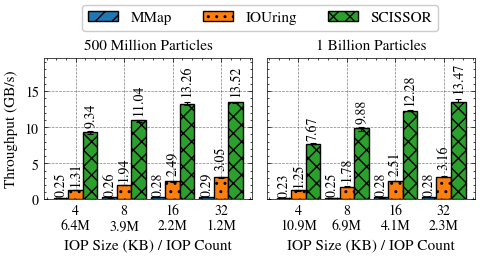

Saved figure to ../figures/e2e_plot_1e-3.pdf


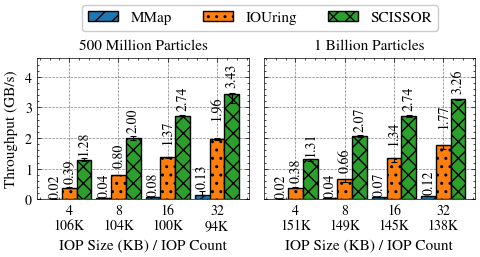

In [8]:
dirname = "../data/evaluation"
generate_all_plots(dirname, error_value="1e-7", save_dir=fig_dir)
generate_all_plots(dirname, error_value="1e-3", save_dir=fig_dir)

## 3.2 Impact of Gaps

In [9]:
def plot_throughput_by_gap(df, chunk_sizes, error_tol, block_size, keep_gaps=None, save_dir=None):
    n = len(chunk_sizes)

    fig, axes = plt.subplots(nrows=1, ncols=n, figsize=(2.5 * n, 2.5), sharey=True)
    # fig, axes = plt.subplots(nrows=1, ncols=n, figsize=FIG_SIZE_HALFCOL, sharey=True)
    
    if n == 1:
        axes = [axes]

    for ax, chunk_size in zip(axes, chunk_sizes):
        subset = df[
            (df["Chunk size"] == chunk_size) &
            (df["Error tolerance"] == error_tol) &
            (df["Block size"] == block_size)
        ].copy()

        if subset.empty:
            print(f"No data after filtering for chunk size {chunk_size}.")
            continue

        for val in subset["Filtered hashes"].unique():
            print(f"{val / 1_000_000:.1f}M")

        gap_sizes = sorted(subset["Offset gap"].unique())
        if keep_gaps is not None:
            gap_sizes = [g for g in gap_sizes if g in keep_gaps.get(chunk_size, gap_sizes)]

        # One row per retained gap, kept as a frame so the spread columns survive
        sel = pd.concat(
            [subset[subset["Offset gap"] == gp].head(1) for gp in gap_sizes],
            ignore_index=True
        )

        throughput_values = []
        wasted_pct_values = []

        GB = 1_000_000_000

        for gp in gap_sizes:
            row = subset[subset["Offset gap"] == gp].iloc[0]
            thrpt = row["Throughput"]
            processed_gb = row["Processed Data GB"]
            wasted_gb = row["Wasted read"] / GB
            total_read_gb = processed_gb + wasted_gb
            wasted_pct = (wasted_gb / total_read_gb) * 100 if total_read_gb > 0 else 0.0
            throughput_values.append(thrpt)
            wasted_pct_values.append(wasted_pct)

        gap_sizes_kb = [gp * chunk_size / 1024 for gp in gap_sizes]
        x = np.arange(len(gap_sizes))
        bar_width = 0.5
        print(wasted_pct_values)

        # ax.bar(
        #     x, throughput_values, width=bar_width,
        #     color=ENGINE_STYLE['SCISSOR']['color'],
        #     hatch=ENGINE_STYLE['SCISSOR']['hatch'],
        #     edgecolor="black", label="Throughput"
        # )
        ax.bar(
            x, throughput_values,
            color=ENGINE_STYLE['SCISSOR']['color'],
            hatch=ENGINE_STYLE['SCISSOR']['hatch'],
            edgecolor="black", label="Throughput",
            yerr=yerr(sel), error_kw=ERRBAR_KW
        )

        iop_counts = [
            subset[subset["Offset gap"] == gp]["IOP count"].iloc[0]
            for gp in gap_sizes
        ]

        def format_iops(count):
            if count >= 1_000_000:
                return f"{count / 1_000_000:.1f}M"
            else:
                return f"{count / 1_000:.0f}K"

        xtick_labels = [
            f"{gap_kb:.0f}\n{format_iops(iop)}"
            for gap_kb, iop in zip(gap_sizes_kb, iop_counts)
        ]

        ax.set_xticks(x)
        ax.set_xticklabels(xtick_labels, fontsize=FONT['tick'])
        ax.tick_params(axis='y', labelsize=FONT['tick'])
        ax.set_xlabel(f"Gap Size (KB) / {chunk_size/1024:.0f} KB IOP", fontsize=FONT['axis'])

        if ax is axes[0]:
            ax.set_ylabel("Throughput (GB/s)", fontsize=FONT['axis'])

        y_max = max(top(sel))
        ax.set_ylim(0, y_max * 1.2)

        for xi, val, t in zip(x, throughput_values, top(sel)):
            ax.text(
                xi, t * 1.02, f"{val:.2f}",
                ha="center", va="bottom", fontsize=FONT['tick']
            )

        ax2 = ax.twinx()
        ax2.plot(x, wasted_pct_values, color="red", marker="o", linewidth=2, label="Unnecessary Read (%)")

        if ax is axes[-1]:
            ax2.set_ylabel("Unnecessary Read (%)", fontsize=FONT['axis'])

        handles1, labels1 = axes[0].get_legend_handles_labels()
        ax2_handles, ax2_labels = ax2.get_legend_handles_labels()

        fig.legend(
            handles1 + ax2_handles, labels1 + ax2_labels,
            loc="upper center", ncol=2, frameon=True,
            bbox_to_anchor=(0.5, 1.1), fontsize=FONT['axis']
        )

    fig.tight_layout()
    if save_dir:
        fname_save = os.path.join(save_dir, f"breakdowngap_multi_{block_size}.pdf")
        # fig.savefig(fname_save, dpi=600)
        fig.savefig(fname_save, bbox_inches='tight', pad_inches=0.02)
        print(f"Saved figure to {fname_save}")

    plt.show()

10.9M
[np.float64(0.0), np.float64(0.0), np.float64(5.883151593928333), np.float64(13.443569539249314), np.float64(20.717321271203044)]
2.3M
[np.float64(0.0), np.float64(0.0), np.float64(1.5619076632913191), np.float64(3.6996093590579413), np.float64(6.8878424995381105)]


Saved figure to ../figures/breakdowngap_multi_33554432.pdf


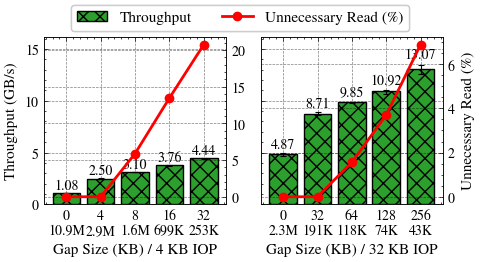

In [10]:
dirname = "../data/evaluation"
breakdown_1B = f"{dirname}/breakdown"
err_tol_dict = {1e-07: '1e-7', 1e-05: '1e-5', 1e-03: '1e-3'}
breakdown_df = load_breakdown(breakdown_1B, err_tol_dict, 'diffio')
# Gap values are in chunk units: gap_kb = gap_chunks * chunk_size / 1024
# 4 KB chunks: 0KB=0, 4KB=1, 16KB=4, 64KB=16
# 32 KB chunks: 0KB=0, 64KB=2, 256KB=8, 512KB=16
# keep_gaps = {
#     4096:  [0, 1, 4, 16],
#     32768: [0, 2, 8, 16],
# }
# keep_gaps = {
#     4096:  [1, 2, 4, 8],
#     32768: [1, 2, 4, 8],
# }
keep_gaps = {
    4096:  [0, 1, 2, 4, 8],
    32768: [0, 1, 2, 4, 8],
}
plot_throughput_by_gap(breakdown_df, [4096, 32768], "1e-7", 33554432,
                       keep_gaps=keep_gaps, save_dir=fig_dir)

## 3.3 Impact of Block Sizes

In [11]:
def plot_throughput_by_blocksize(df, chunk_sizes, error_tol, offset_gap, keep_block_sizes=None, save_dir=None):
    n = len(chunk_sizes)
    # fig, axes = plt.subplots(1, n, figsize=(4 * n, 3), sharey=True)
    fig, axes = plt.subplots(1, n, figsize=(2.5 * n, 2.5), sharey=True)

    if n == 1:
        axes = [axes]

    for ax, chunk_size in zip(axes, chunk_sizes):
        subset = df[
            (df["Chunk size"] == chunk_size) &
            (df["Error tolerance"] == error_tol) &
            (df["Offset gap"] == offset_gap)
        ].copy()

        if subset.empty:
            print(f"No data after filtering for chunk size {chunk_size}.")
            continue

        print(subset["IOP count"].unique())
        print(subset["Filtered hashes"].unique())

        block_sizes = sorted(subset["Block size"].unique())
        if keep_block_sizes is not None:
            block_sizes = [b for b in block_sizes if b in keep_block_sizes.get(chunk_size, block_sizes)]
        # One row per retained block size, kept as a frame for the spread columns
        sel = pd.concat(
            [subset[subset["Block size"] == bs].head(1) for bs in block_sizes],
            ignore_index=True
        )
        throughput_values = list(sel["Throughput"])

        block_sizes_mib = [bs / (1024 * 1024) for bs in block_sizes]

        x = np.arange(len(block_sizes))
        bar_width = 0.5

        ax.bar(
            x, throughput_values,
            color=ENGINE_STYLE['SCISSOR']['color'],
            hatch=ENGINE_STYLE['SCISSOR']['hatch'],
            edgecolor="black", label="Throughput",
            yerr=yerr(sel), error_kw=ERRBAR_KW
        )

        ax.set_xlabel(f"Batch Size (MB) / {chunk_size / 1024:.0f} KB IOPs", fontsize=FONT['axis'])
        ax.tick_params(axis='y', labelsize=FONT['tick'])
        ax.set_xticks(x)
        ax.set_xticklabels([f"{bs:.0f}" for bs in block_sizes_mib], fontsize=FONT['tick'])

        y_max = max(top(sel))
        ax.set_ylim(0, y_max * 1.2)

        for xi, val, t in zip(x, throughput_values, top(sel)):
            ax.text(
                xi, t * 1.04, f"{val:.2f}",
                ha="center", va="bottom",
                fontsize=FONT['tick'], color="black"
            )

    axes[0].set_ylabel("Throughput (GB/s)", fontsize=FONT['axis'])

    if save_dir:
        fname_save = os.path.join(save_dir, f"breakdownbs_chunks_{offset_gap}.pdf")
        fig.tight_layout()
        # fig.savefig(fname_save, dpi=600)
        fig.savefig(fname_save, bbox_inches='tight', pad_inches=0.02)
        print(f"Saved figure to {fname_save}")

    plt.show()

[2932043]
[10924880]
[191076]
[2300638]


Saved figure to ../figures/breakdownbs_chunks_1.pdf


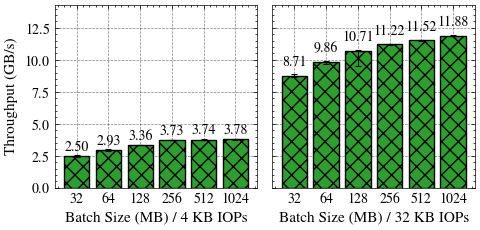

In [12]:
dirname = "../data/evaluation"
breakdown_1B = f"{dirname}/breakdown"
err_tol_dict = {1e-07: '1e-7', 1e-05: '1e-5', 1e-03: '1e-3'}
breakdown_df = load_breakdown(breakdown_1B, err_tol_dict, 'diffio')
# keep_block_sizes = {
#     4096:  [4194304, 33554432, 67108864, 134217728, 2147483648],   # 4, 32, 64, 128, 2048 MB
#     32768: [33554432, 134217728, 1073741824, 4294967296, 17179869184],  # 32, 128, 1024, 4096, 16384 MB
# }
# keep_block_sizes = {
#     4096:  [33554432, 67108864, 134217728, 268435456],  # 32, 64, 128, 256 MB
#     32768: [33554432, 67108864, 134217728, 268435456],  # 32, 64, 128, 256 MB
# }
# keep_block_sizes = {
#     4096:  [33554432, 67108864, 134217728, 268435456, 536870912, 2147483648],  # 32, 64, 128, 256 MB
#     32768: [33554432, 67108864, 134217728, 268435456, 536870912, 2147483648],  # 32, 64, 128, 256 MB
# }
keep_block_sizes = {
    4096:  [33554432, 67108864, 134217728, 268435456, 536870912, 1073741824],  # 32, 64, 128, 256 MB
    32768: [33554432, 67108864, 134217728, 268435456, 536870912, 1073741824],  # 32, 64, 128, 256 MB
}
plot_throughput_by_blocksize(breakdown_df, [4096, 32768], "1e-7", 1,
                             keep_block_sizes=keep_block_sizes, save_dir=fig_dir)

## 3.4 Regressor Error Margin


In [13]:
dirname = "../data/evaluation"
_error_map   = {1e-07: '1e-7', 1e-03: '1e-3', 1e-05: '1e-5'}
_err_tol_dict = {1e-07: '1e-7', 1e-05: '1e-5', 1e-03: '1e-3'}
_GB = 1_000_000_000

# Load e2e DiffIO 1B (same logic as generate_all_plots)
_dfs = [pd.read_csv(f) for f in glob.glob(
    os.path.join(f"{dirname}/e2e/DiffIO/np1000-01bil", "*.csv")
)]
_df = pd.concat(_dfs, ignore_index=True)
_df['Run'] = _df.groupby(
    ['Rank', 'File', 'Chunk size', 'Error tolerance', 'Block size', 'Offset gap']
).cumcount()
_df = _df[_df['Num hash comparisons'] != 0]
_df = _df.rename(columns={'Compare direct time': 'Compare time'})
_df['Error tolerance'] = _df['Error tolerance'].map(_error_map)
_df['Processed Data GB'] = (_df['Filtered hashes'] * _df['Chunk size'] * 2) / _GB
_df['rank_throughput'] = _df['Processed Data GB'] / _df['Compare time']

# Extract modal (Block size, Offset gap) per (Chunk size, Error tolerance)
# Each rank independently selects its best params. modal = most frequently chosen pair.
_params = (
    _df.groupby(['Chunk size', 'Error tolerance'])
       .apply(lambda g: g[['Block size', 'Offset gap']].mode().iloc[0])
       .reset_index()
)
_params['Block size MB'] = _params['Block size'] / (1024 * 1024)
scissor_params_df = _params

_agg = (
    _df.groupby(['Chunk size', 'Error tolerance', 'Run'])
       .agg({'Processed Data GB': 'sum', 'Compare time': 'max',
             'Filtered hashes': 'sum', 'rank_throughput': 'sum'})
       .reset_index()
)
_agg['Throughput'] = _agg['rank_throughput']
diffio_1b_e2e_df = median_with_spread(_agg, ['Chunk size', 'Error tolerance'])

# Load breakdown sweep data
breakdown_df = load_breakdown(f"{dirname}/breakdown", _err_tol_dict, 'diffio')

print(f"E2E DiffIO 1B: {len(diffio_1b_e2e_df)} (chunk_size, error_tol) rows")
print(f"Breakdown:     {len(breakdown_df)} (chunk_size, error_tol, gap, blocksize) rows")
print(f"SCISSOR params: {len(scissor_params_df)} rows")
print(scissor_params_df[['Chunk size', 'Error tolerance', 'Block size MB', 'Offset gap']].to_string(index=False))
diffio_1b_e2e_df


E2E DiffIO 1B: 12 (chunk_size, error_tol) rows
Breakdown:     198 (chunk_size, error_tol, gap, blocksize) rows
SCISSOR params: 12 rows
 Chunk size Error tolerance  Block size MB  Offset gap
       4096            1e-3           64.0        16.0
       4096            1e-5         1024.0        16.0
       4096            1e-7         1024.0        16.0
       8192            1e-3          128.0        16.0
       8192            1e-5         1024.0        16.0
       8192            1e-7         1024.0        16.0
      16384            1e-3          256.0        16.0
      16384            1e-5         1024.0        16.0
      16384            1e-7         1024.0        16.0
      32768            1e-3          512.0        16.0
      32768            1e-5         1024.0        16.0
      32768            1e-7          512.0        16.0


/tmp/ipykernel_51314/2234688670.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  _df.groupby(['Chunk size', 'Error tolerance'])


,Chunk size,Error tolerance,Run,Processed Data GB,Compare time,Filtered hashes,rank_throughput,Throughput,Throughput lo,Throughput hi,Throughput runs
0,4096,1e-3,1.0,1.238426,1.278128,151175.0,1.306118,1.306118,1.254906,1.330487,3
1,4096,1e-5,1.0,28.875637,9.855936,3524858.0,4.545767,4.545767,4.531318,4.578145,3
2,4096,1e-7,1.0,89.496617,13.066584,10924880.0,7.673923,7.673923,7.657922,7.756128,3
3,8192,1e-3,1.0,2.435760,1.548037,148667.0,2.073852,2.073852,2.041118,2.096587,3
4,8192,1e-5,1.0,41.625256,12.145511,2540604.0,5.689502,5.689502,5.056049,5.714543,3
5,8192,1e-7,1.0,113.510384,15.022262,6928124.0,9.881112,9.881112,9.541114,10.055995,3
6,16384,1e-3,1.0,4.743496,2.422969,144760.0,2.735300,2.735300,2.679819,2.746498,3
7,16384,1e-5,1.0,56.791204,15.243185,1733130.0,6.150553,6.150553,6.144869,6.168229,3
8,16384,1e-7,1.0,134.452642,12.310224,4103169.0,12.283631,12.283631,12.256410,12.393254,3
9,32768,1e-3,1.0,9.044034,3.789141,138001.0,3.262151,3.262151,3.250345,3.289163,3


In [14]:
def plot_regressor_margin(e2e_df, breakdown_df, scissor_params_df=None, chunk_sizes=None, error_tol='1e-7', save_dir=None):
    """
    Single grouped-bar figure comparing SCISSOR regressor throughput (e2e, 1B)
    against the oracle best from the (Offset gap, Block size) sweep (breakdown).
    Each bar group = one chunk size, with two bars per group (Regressor, Oracle Best).
    If chunk_sizes is None or empty, all chunk sizes present in both datasets are used.
    Prints regressor-selected and oracle-best (gap, batch) for each configuration.
    """
    # Resolve chunk sizes from data intersection when not provided
    if not chunk_sizes:
        available = (
            set(e2e_df[e2e_df['Error tolerance'] == error_tol]['Chunk size']) &
            set(breakdown_df[breakdown_df['Error tolerance'] == error_tol]['Chunk size'])
        )
        chunk_sizes = sorted(available)

    regressor_tps = []
    regressor_lo  = []
    regressor_hi  = []
    oracle_tps    = []
    oracle_lo     = []
    oracle_hi     = []
    oracle_cfgs   = []   # (best_gap, best_block_size_mb) for annotation
    valid_chunks  = []

    print(f"\n{'='*60}")
    print(f"Regressor vs Oracle: error_tol={error_tol}")
    print(f"{'='*60}")

    for chunk_size in chunk_sizes:
        e2e_row = e2e_df[
            (e2e_df['Chunk size'] == chunk_size) &
            (e2e_df['Error tolerance'] == error_tol)
        ]
        bd_sub = breakdown_df[
            (breakdown_df['Chunk size'] == chunk_size) &
            (breakdown_df['Error tolerance'] == error_tol)
        ]
        if e2e_row.empty or bd_sub.empty:
            continue

        best_row = bd_sub.loc[bd_sub['Throughput'].idxmax()]
        regressor_tp = e2e_row['Throughput'].values[0]
        oracle_tp    = best_row['Throughput']
        best_gap     = int(best_row['Offset gap'])
        best_bs_mb   = best_row['Block size'] / (1024 * 1024)

        r_lo, r_hi = spread_of(e2e_row.iloc[0])
        o_lo, o_hi = spread_of(best_row)

        regressor_tps.append(regressor_tp)
        regressor_lo.append(r_lo)
        regressor_hi.append(r_hi)
        oracle_tps.append(oracle_tp)
        oracle_lo.append(o_lo)
        oracle_hi.append(o_hi)
        oracle_cfgs.append((best_gap, best_bs_mb))
        valid_chunks.append(chunk_size)

        # Look up regressor-selected params if available
        chunk_kb = chunk_size // 1024
        print(f"\nChunk={chunk_kb} KB | error_tol={error_tol}")

        if scissor_params_df is not None:
            sc_row = scissor_params_df[
                (scissor_params_df['Chunk size'] == chunk_size) &
                (scissor_params_df['Error tolerance'] == error_tol)
            ]
            if not sc_row.empty:
                sc_gap    = int(sc_row['Offset gap'].values[0])
                sc_bs_mb  = sc_row['Block size MB'].values[0]
                sc_gap_kb = sc_gap * chunk_size / 1024
                print(f"  SCISSOR (regressor): tp={regressor_tp:.4f} GB/s  "
                      f"gap={sc_gap} chunks ({sc_gap_kb:.0f} KB)  batch={sc_bs_mb:.0f} MB")
            else:
                print(f"  SCISSOR (regressor): tp={regressor_tp:.4f} GB/s  [params not available]")
        else:
            print(f"  SCISSOR (regressor): tp={regressor_tp:.4f} GB/s  [scissor_params_df not provided]")

        oracle_gap_kb = best_gap * chunk_size / 1024
        margin_pct    = (oracle_tp - regressor_tp) / oracle_tp * 100
        print(f"  Oracle best:         tp={oracle_tp:.4f} GB/s  "
              f"gap={best_gap} chunks ({oracle_gap_kb:.0f} KB)  batch={best_bs_mb:.0f} MB")
        print(f"  Margin:              -{margin_pct:.1f}%")

    print(f"{'='*60}\n")

    if not valid_chunks:
        print(f"No data for error_tol={error_tol}")
        return

    n     = len(valid_chunks)
    bar_w = 0.35
    x     = np.arange(n)
    reg_err = yerr(pd.DataFrame({'Throughput': regressor_tps,
                                 SPREAD_LO: regressor_lo, SPREAD_HI: regressor_hi}))
    orc_err = yerr(pd.DataFrame({'Throughput': oracle_tps,
                                 SPREAD_LO: oracle_lo, SPREAD_HI: oracle_hi}))
    reg_top = np.fmax(regressor_tps, regressor_hi)
    orc_top = np.fmax(oracle_tps, oracle_hi)
    y_max = max(max(reg_top), max(orc_top))

    # fig, ax = plt.subplots(figsize=(max(3.3, 1.8 * n), 2.5))
    fig, ax = plt.subplots(figsize=FIG_SIZE_HALFCOL)

    ax.bar(x - bar_w / 2, regressor_tps, width=bar_w,
           color=ENGINE_STYLE['SCISSOR']['color'],
           hatch=ENGINE_STYLE['SCISSOR']['hatch'],
           edgecolor='black', linewidth=0.8, label='Regressor',
           yerr=reg_err, error_kw=ERRBAR_KW)
    ax.bar(x + bar_w / 2, oracle_tps, width=bar_w,
           color=ENGINE_STYLE['IOUring']['color'],
           hatch=ENGINE_STYLE['IOUring']['hatch'],
           edgecolor='black', linewidth=0.8, label='Exhaustive Best',
           yerr=orc_err, error_kw=ERRBAR_KW)

    # Value labels on regressor bars (above the whisker)
    for xi, val, t in zip(x, regressor_tps, reg_top):
        ax.text(xi - bar_w / 2, t + y_max * 0.01, f'{val:.2f}',
                ha='center', va='bottom', fontsize=FONT['annot'], rotation=90)

    # Value labels on oracle bars
    for xi, val, t, (gap, bs_mb) in zip(x, oracle_tps, orc_top, oracle_cfgs):
        ax.text(xi + bar_w / 2, t + y_max * 0.03, f'{val:.2f}',
                ha='center', va='bottom', fontsize=FONT['annot'], rotation=90)

    # Margin percentage above each group
    for xi, r_tp, o_tp, t in zip(x, regressor_tps, oracle_tps, orc_top):
        margin_pct = (o_tp - r_tp) / o_tp * 100
        ax.text(xi, t + y_max * 0.3, f'-{margin_pct:.1f}%',
                ha='center', va='bottom', fontsize=FONT['annot'],
                color='darkred', fontweight='bold')

    ax.set_xticks(x)
    ax.set_xticklabels([f'{cs // 1024} KB' for cs in valid_chunks], fontsize=FONT['tick'])
    ax.set_xlabel('IOP Size', fontsize=FONT['axis'])
    ax.set_ylabel('Throughput (GB/s)', fontsize=FONT['axis'])
    ax.set_ylim(0, y_max * 1.45)
    ax.tick_params(axis='y', labelsize=FONT['tick'])
    ax.grid(True, axis='y', linestyle=':', alpha=0.4)

    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=2,
               bbox_to_anchor=(0.56, 1.1), fontsize=FONT['axis'], frameon=True)
    fig.tight_layout()

    if save_dir:
        fname = os.path.join(save_dir, f'regressor_margin_{error_tol}.pdf')
        fig.savefig(fname, bbox_inches='tight', pad_inches=0.02, dpi=600)
        print(f'Saved figure to {fname}')

    plt.show()



Regressor vs Oracle: error_tol=1e-7

Chunk=4 KB | error_tol=1e-7
  SCISSOR (regressor): tp=7.6739 GB/s  gap=16 chunks (64 KB)  batch=1024 MB
  Oracle best:         tp=8.2363 GB/s  gap=16 chunks (64 KB)  batch=2048 MB
  Margin:              -6.8%

Chunk=8 KB | error_tol=1e-7
  SCISSOR (regressor): tp=9.8811 GB/s  gap=16 chunks (128 KB)  batch=1024 MB
  Oracle best:         tp=10.0362 GB/s  gap=16 chunks (128 KB)  batch=256 MB
  Margin:              -1.5%

Chunk=16 KB | error_tol=1e-7
  SCISSOR (regressor): tp=12.2836 GB/s  gap=16 chunks (256 KB)  batch=1024 MB
  Oracle best:         tp=13.1274 GB/s  gap=16 chunks (256 KB)  batch=512 MB
  Margin:              -6.4%

Chunk=32 KB | error_tol=1e-7
  SCISSOR (regressor): tp=13.4693 GB/s  gap=16 chunks (512 KB)  batch=512 MB
  Oracle best:         tp=15.9808 GB/s  gap=8 chunks (256 KB)  batch=8192 MB
  Margin:              -15.7%



Saved figure to ../figures/regressor_margin_1e-7.pdf


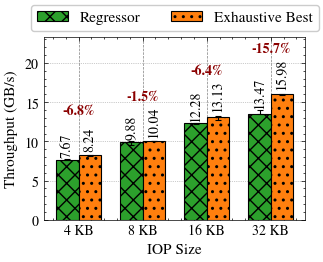

In [15]:
plot_regressor_margin(diffio_1b_e2e_df, breakdown_df, scissor_params_df, error_tol='1e-7', save_dir=fig_dir)

## 3.4 Queue Depth and Completion Queue Depth

In [16]:
dirname = "../data/evaluation"
breakdown_1B = f"{dirname}/qdvar"
err_tol_dict = {1e-07: '1e-7', 1e-05: '1e-5', 1e-03: '1e-3'}
diffio_breakdown_df = load_and_process(
    f"{breakdown_1B}/diffio", err_tol_dict, ['Queue depth', 'CQueue depth']
)
uring_breakdown_df = load_and_process(
    f"{breakdown_1B}/liburing", err_tol_dict, ['Queue depth']
)

In [17]:
def plot_qdepth_diffio_vs_uring(
    diffio_df, uring_df, chunk_sizes, error_tol, cqdepth, save_dir=None
):
    n = len(chunk_sizes)
    # fig, axes = plt.subplots(1, n, figsize=(4.5 * n, 3), sharey=True)
    fig, axes = plt.subplots(1, n, figsize=FIG_SIZE_HALFCOL, sharey=True)

    if n == 1:
        axes = [axes]

    colors = [ENGINE_STYLE['IOUring']['color'], ENGINE_STYLE['SCISSOR']['color']]
    hatches = [ENGINE_STYLE['IOUring']['hatch'], ENGINE_STYLE['SCISSOR']['hatch']]
    ref_lines = {4096: 7.68, 32768: 13.47}
    for ax, chunk_size in zip(axes, chunk_sizes):
        ddf = diffio_df[
            (diffio_df["Chunk size"] == chunk_size) &
            (diffio_df["Error tolerance"] == error_tol) &
            (diffio_df["CQueue depth"] == cqdepth)
        ].copy()

        udf = uring_df[
            (uring_df["Chunk size"] == chunk_size) &
            (uring_df["Error tolerance"] == error_tol)
        ].copy()

        if ddf.empty or udf.empty:
            print(f"No data for chunk size {chunk_size}.")
            continue

        # qdepths = sorted(set(ddf["Queue depth"]) & set(udf["Queue depth"]))
        qdepths = [128, 512, 2048, 8192]

        # Keep whole rows so the spread columns survive the reindex
        d_sel = ddf.set_index("Queue depth").loc[qdepths].reset_index()
        u_sel = udf.set_index("Queue depth").loc[qdepths].reset_index()
        d_thrpt = d_sel["Throughput"]
        u_thrpt = u_sel["Throughput"]

        x = np.arange(len(qdepths))
        w = 0.35

        b1 = ax.bar(
            x - w / 2, u_thrpt, width=w, label="IOUring",
            color=colors[0], hatch=hatches[0], edgecolor="black",
            yerr=yerr(u_sel), error_kw=ERRBAR_KW
        )
        b2 = ax.bar(
            x + w / 2, d_thrpt, width=w, label="SCISSOR",
            color=colors[1], hatch=hatches[1], edgecolor="black",
            yerr=yerr(d_sel), error_kw=ERRBAR_KW
        )

        ax.set_xticks(x)
        ax.set_xticklabels(qdepths, fontsize=FONT['tick'])
        # ax.set_xlabel(f"Submission Queue Depth ({chunk_size / 1024:.0f} KB IOPs)", fontsize=FONT['axis'])
        ax.set_xlabel(f"Submission Queue Depth", fontsize=FONT['axis'])
        ax.set_ylim(0, max(max(top(d_sel)), max(top(u_sel))) * 1.2)

        ax.axhline(
            y=ref_lines[chunk_size], color="red", linestyle="--",
            linewidth=2
        )

        for bar, t in zip(b1, top(u_sel)):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                t * 1.04,
                f"{bar.get_height():.2f}",
                ha="center", va="bottom",
                fontsize=FONT['tick'], rotation=90
            )

        for bar, t in zip(b2, top(d_sel)):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                t * 1.04,
                f"{bar.get_height():.2f}",
                ha="center", va="bottom",
                fontsize=FONT['tick'], rotation=90
            )

    axes[0].set_ylabel("Throughput (GB/s)", fontsize=FONT['axis'])

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels, loc="upper center", ncol=2, frameon=True,
        bbox_to_anchor=(0.55, 1.1), fontsize=FONT['axis']
    )

    fig.tight_layout()

    if save_dir:
        fname = f"qdepth_diffio_vs_uring_cq{cqdepth}_{chunk_sizes[0]}.pdf"
        # fig.savefig(os.path.join(save_dir, fname), dpi=600)
        fig.savefig(os.path.join(save_dir, fname), bbox_inches='tight', pad_inches=0.02)
        print(f"Saved figure to {fname}")

    plt.show()

Saved figure to qdepth_diffio_vs_uring_cq512_4096.pdf


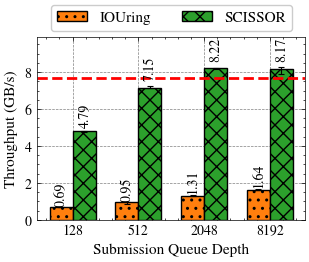

In [18]:
plot_qdepth_diffio_vs_uring(
    diffio_breakdown_df, uring_breakdown_df, [4096], "1e-7", 512, save_dir=fig_dir
)
# plot_qdepth_diffio_vs_uring(
#     diffio_breakdown_df, uring_breakdown_df, [32768], "1e-7", 1024, save_dir=fig_dir
# )

In [19]:
def plot_cqdepth_by_qdepth(
    diffio_df, chunk_sizes=(4096, 32768), error_tol=None,
    keep_cqdepths=None, save_dir=None
):
    def _fmt_val(val) -> str:
        if val >= 1000:
            return f'{val // 1000}K'
        else:
            return val
    
    all_cqdepths = [32, 128, 512, 2048, 8192]
    cqdepths = [c for c in all_cqdepths if keep_cqdepths is None or c in keep_cqdepths]
    # qdepths = [128, 2048, 32768]
    qdepths = [128, 512, 2048]

    x = np.arange(len(cqdepths))
    w = 0.8 / len(qdepths)

    COLORS = [
        "#000000", "#E69F00", "#56B4E9", "#009E73",
        "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#FF0000"
    ]
    HATCHES = ["", "//", "\\\\", "xx", "..", "++", "--", "oo", ""]

    qd_style = {
        qd: {"color": COLORS[i % len(COLORS)], "hatch": HATCHES[i % len(HATCHES)]}
        for i, qd in enumerate(qdepths)
    }
    n = len(chunk_sizes)
    fig, axes = plt.subplots(1, n, figsize=FIG_SIZE_HALFCOL, sharey=True)
    if n == 1:
        axes = [axes]

    max_val = 0

    ref_lines = {4096: 7.68, 32768: 13.47}
    # ref_lines = {4096: 6.8, 32768: 12.0}
    xlabel_suffix = {4096: "(4 KB IOPs)", 32768: "(32 KB IOPs)"}

    for ax, chunk_size in zip(axes, chunk_sizes):
        ddf = diffio_df[
            (diffio_df["Chunk size"] == chunk_size)
            & ((diffio_df["Error tolerance"] == error_tol) if error_tol is not None else True)
        ].copy()

        if ddf.empty:
            raise ValueError(f"No data after filtering for chunk size {chunk_size}")

        for i, qd in enumerate(qdepths):
            sel = (
                ddf[ddf["Queue depth"] == qd]
                .set_index("CQueue depth")
                .loc[cqdepths]
                .reset_index()
            )
            vals = sel["Throughput"]

            max_val = max(max_val, max(top(sel)))

            bars = ax.bar(
                x + i * w - (len(qdepths) - 1) * w / 2,
                vals, width=w,
                # label=f"SQD={qd}",
                label=f"SQ={qd}",
                color=qd_style[qd]["color"],
                hatch=qd_style[qd]["hatch"],
                edgecolor="black",
                yerr=yerr(sel), error_kw=ERRBAR_KW
            )

            for bar, t in zip(bars, top(sel)):
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    t * 1.02,
                    f"{bar.get_height():.2f}",
                    ha="center", va="bottom",
                    fontsize=FONT['annot'],
                    rotation=90
                )

        # ax.axhline(
        #     y=ref_lines[chunk_size], color="red", linestyle="--",
        #     linewidth=2, label="SCISSOR"
        # )
        ax.axhline(
            y=ref_lines[chunk_size], color="red", linestyle="--",
            linewidth=2
        )

        ax.set_ylim(0, max_val * 1.3)
        ax.set_xticks(x)
        ax.set_xticklabels(cqdepths, fontsize=FONT['tick'])
        # ax.set_xlabel(
        #     f"Completion Queue Depth\n{xlabel_suffix[chunk_size]}",
        #     fontsize=FONT['axis']
        # )
        ax.set_xlabel(
            f"Completion Queue Depth",
            fontsize=FONT['axis']
        )
        ax.tick_params(axis="y", labelsize=FONT['tick'])
        ax.grid(axis="y", linestyle="--", alpha=0.4)

    axes[0].set_ylabel("Throughput (GB/s)", fontsize=FONT['axis'])

    handles, labels = axes[0].get_legend_handles_labels()
    # fig.legend(
    #     handles, labels,
    #     ncols=len(qdepths) + 1, loc="upper center", frameon=True,
    #     bbox_to_anchor=(0.5, 1.03), fontsize=FONT['tick']
    # )
    fig.legend(
        handles, labels,
        ncols=3, loc="upper center", frameon=True, columnspacing=1,
        bbox_to_anchor=(0.5, 1.05), fontsize=FONT['axis']
    )

    plt.tight_layout(rect=[0, 0, 1, 0.95])

    if save_dir:
        fname = "cqdepth_by_qdepth_dual_chunks_new.pdf"
        # plt.savefig(os.path.join(save_dir, fname), dpi=300)
        fig.savefig(os.path.join(save_dir, fname), bbox_inches='tight', pad_inches=0.02)
        print(f"Saved figure to {fname}")

    plt.show()

Saved figure to cqdepth_by_qdepth_dual_chunks_new.pdf


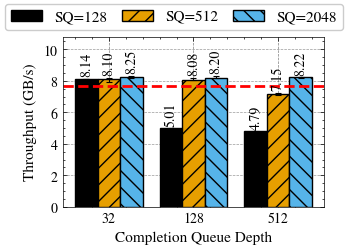

In [20]:
# plot_cqdepth_by_qdepth(diffio_breakdown_df, error_tol="1e-7", chunk_sizes=[4096],
#                        keep_cqdepths=[32, 128, 8192], save_dir=fig_dir)
plot_cqdepth_by_qdepth(diffio_breakdown_df, error_tol="1e-7", chunk_sizes=[4096],
                       keep_cqdepths=[32, 128, 512], save_dir=fig_dir)

## 3.5 Scalability Analysis

In [21]:
def load_and_process_weak_scaling(dirpath, error_map, extra_cols=None, nfiles=2):
    """
    Load weak-scaling data with correct throughput aggregation.
    Ranks run in parallel behind MPI_Barrier:
      - Processed Data GB: sum across ranks (each owns its shard)
      - Compare time:      max across ranks (wall time = slowest rank)
    Throughput = Σ(Processed Data GB) / max(Compare time).
    """
    if extra_cols is None:
        extra_cols = []

    csvs = glob.glob(os.path.join(dirpath, "*.csv"))
    dfs = [pd.read_csv(f) for f in csvs]
    df = pd.concat(dfs, ignore_index=True)

    df["Run"] = (
        df.groupby(["Rank", "File", "Chunk size", "Error tolerance"] + extra_cols)
          .cumcount()
    )

    df = df[df["Num hash comparisons"] != 0]

    GB = 1_000_000_000
    df = df.rename(columns={"Compare direct time": "Compare time"})

    df[["ckpt_rank", "ckpt_id"]] = df["File"].str.extract(r"-combined-(\d+)-(\d+)\.dat")
    df["ckptID"] = df["ckpt_rank"] + "-" + df["ckpt_id"]

    df["Error tolerance"] = df["Error tolerance"].map(error_map)

    # Per-rank data volume
    df["Processed Data GB"] = (df["Filtered hashes"] * df["Chunk size"] * nfiles) / GB

    keep = [
        "Run", "Rank", "Chunk size", "Error tolerance",
        "Processed Data GB", "Compare time"
    ] + extra_cols
    df = df[keep]

    # Formula B: Σ_r(bytes_r / time_r), summed per-rank throughputs.
    df["rank_throughput"] = df["Processed Data GB"] / df["Compare time"]
    per_run = (
        df.groupby(["Chunk size", "Error tolerance", "Run"] + extra_cols)
          .agg({"Processed Data GB": "sum", "Compare time": "max",
                "rank_throughput": "sum"})
          .reset_index()
    )
    per_run["Throughput"] = per_run["rank_throughput"]

    # Median across runs, plus the run-to-run spread used for error bars
    df_med = median_with_spread(
        per_run, ["Chunk size", "Error tolerance"] + extra_cols
    )

    return df_med

In [22]:
def plot_nnode_diffio_vs_uring(diffio_df, uring_df, chunk_sizes, error_tol, save_dir=None):
    n = len(chunk_sizes)
    # fig, axes = plt.subplots(1, n, figsize=(4 * n, 3), sharey=True)
    fig, axes = plt.subplots(1, n, figsize=FIG_SIZE_HALFCOL, sharey=True)

    if n == 1:
        axes = [axes]

    colors = [ENGINE_STYLE['IOUring']['color'], ENGINE_STYLE['SCISSOR']['color']]
    hatches = [ENGINE_STYLE['IOUring']['hatch'], ENGINE_STYLE['SCISSOR']['hatch']]

    for ax, chunk_size in zip(axes, chunk_sizes):
        ddf = diffio_df[
            (diffio_df["Chunk size"] == chunk_size) &
            (diffio_df["Error tolerance"] == error_tol)
        ]

        udf = uring_df[
            (uring_df["Chunk size"] == chunk_size) &
            (uring_df["Error tolerance"] == error_tol)
        ]

        if ddf.empty or udf.empty:
            continue

        nprocs = sorted(set(ddf["nproc"]) & set(udf["nproc"]))

        # Keep whole rows so the spread columns survive the reindex
        d_sel = ddf.set_index("nproc").loc[nprocs].reset_index()
        u_sel = udf.set_index("nproc").loc[nprocs].reset_index()
        d_thrpt = d_sel["Throughput"]
        u_thrpt = u_sel["Throughput"]

        x = np.arange(len(nprocs))
        w = 0.35

        b1 = ax.bar(
            x - w / 2, u_thrpt, width=w, label="IOUring",
            color=colors[0], hatch=hatches[0], edgecolor="black",
            yerr=yerr(u_sel), error_kw=ERRBAR_KW
        )
        b2 = ax.bar(
            x + w / 2, d_thrpt, width=w, label="SCISSOR",
            color=colors[1], hatch=hatches[1], edgecolor="black",
            yerr=yerr(d_sel), error_kw=ERRBAR_KW
        )

        ax.set_xticks(x)
        ax.set_xticklabels(nprocs, fontsize=FONT['tick'])
        ax.set_xlabel(
            f"Number of Processes (IOP Size = {chunk_size / 1024:.0f} KB)",
            fontsize=FONT['axis']
        )

        ymax = max(max(top(d_sel)), max(top(u_sel)))
        ax.set_ylim(0, ymax * 1.45)

        for bar, t in zip(b1, top(u_sel)):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                t * 1.07,
                f"{bar.get_height():.2f}",
                ha="center", va="bottom",
                fontsize=FONT['tick'], rotation=90
            )

        for bar, t in zip(b2, top(d_sel)):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                t * 1.05,
                f"{bar.get_height():.2f}",
                ha="center", va="bottom",
                fontsize=FONT['tick'], rotation=90
            )

    axes[0].set_ylabel("Throughput (GB/s)", fontsize=FONT['axis'])

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, labels, loc="upper center", ncol=3, frameon=True,
        bbox_to_anchor=(0.57, 1.1), fontsize=FONT['axis']
    )

    fig.tight_layout()

    if save_dir:
        fname = "nnode_scalability.pdf"
        # fig.savefig(os.path.join(save_dir, fname), dpi=600)
        fig.savefig(os.path.join(save_dir, fname), bbox_inches='tight', pad_inches=0.02)

    plt.show()

In [23]:
from pathlib import Path

RANKS_PER_NODE = 2  # 2 MPI ranks per node used in scalability experiments

dirname = "../data/scalability"
err_tol_dict = {1e-07: '1e-7', 1e-05: '1e-5', 1e-03: '1e-3'}

node_folders = [item.name for item in Path(f"{dirname}/DiffIO").iterdir() if item.is_dir()]

diffio_scale_dfs = []
uring_scale_dfs = []

for ndir in node_folders:
    nnode = int(ndir.split("-")[-1])
    nproc = nnode * RANKS_PER_NODE

    node_diffio_df = load_and_process_weak_scaling(
        f"{dirname}/DiffIO/{ndir}", err_tol_dict, ['Queue depth', 'CQueue depth']
    )
    node_uring_df = load_and_process_weak_scaling(
        f"{dirname}/IOUring/{ndir}", err_tol_dict, ['Queue depth']
    )
    node_diffio_df["nproc"] = nproc
    node_uring_df["nproc"] = nproc
    diffio_scale_dfs.append(node_diffio_df)
    uring_scale_dfs.append(node_uring_df)

diffio_scale_df = pd.concat(diffio_scale_dfs, ignore_index=True)
uring_scale_df = pd.concat(uring_scale_dfs, ignore_index=True)

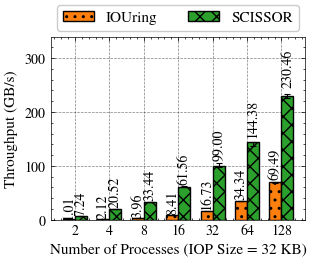

In [24]:
plot_nnode_diffio_vs_uring(diffio_scale_df, uring_scale_df, [32768], "1e-7", save_dir=fig_dir)